# Análise exploratória: perfis de aparelho associados às falhas de login (App EPX, Android)

Projeto de Extensão em Ciência de Dados (SM262207) · Centro Universitário Unicarioca

> **Dados simulados.** Este notebook usa a base de incidentes **simulada** (Plano B), gerada por
> `src/simular_incidentes.py` com semente fixa e calibrada só com parâmetros agregados da análise real.
> **Nenhum incidente exibido aqui é real.** O catálogo de aparelhos é o export real do Google Play Console.
> Os resultados são **associações, não causas**. Por ser simulada, a base serve para demonstrar e validar o
> método, não para afirmar conclusões sobre aparelhos reais.

**Como ler.** Cada gráfico é seguido de duas respostas curtas: *o que este dado está nos dizendo?* e
*por que isso é relevante?* Os números dos textos são calculados na execução, então acompanham os dados.

**Como executar.** A partir da raiz do repositório: `pip install -r requirements-notebook.txt` e abrir este arquivo
no Jupyter ou no VS Code. O notebook refaz o pipeline inteiro (catálogo, simulação, extração, taxas, modelo e grafo)
e, na última seção, compara o resultado com os CSVs de `data/processed/`.

**Roteiro**
1. Dados de entrada
2. Qualidade dos dados (data profiling)
3. Panorama dos incidentes
4. Taxa por grupo (contagem absoluta engana)
5. Perfis de aparelho
6. Modelo de Poisson
7. Grafo de atributos
8. Verificação de reprodutibilidade
9. Limitações e conclusões

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(RAIZ))

import matplotlib
import matplotlib.dates
import matplotlib.pyplot as plt
import matplotlib.ticker
import networkx as nx
import numpy as np
import pandas as pd
import statsmodels
from IPython.display import Markdown, display

from dashboard.componentes import SINTOMAS, STATUS
from src import analise, catalogo, config, extracao, grafo, perfis
from src.pipeline import funil
from src.simular_incidentes import simular

np.random.seed(config.SEED)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"statsmodels {statsmodels.__version__} | networkx {nx.__version__} | matplotlib {matplotlib.__version__}")
print(f"Semente fixa (src/config.py): SEED = {config.SEED} | K_MIN = {config.K_MIN} | regra de SDK = '{config.REGRA_SDK}'")

Python 3.14.8 | pandas 3.0.6 | numpy 2.5.4 | statsmodels 0.15.0 | networkx 3.7 | matplotlib 3.11.2
Semente fixa (src/config.py): SEED = 20261014 | K_MIN = 5 | regra de SDK = 'max'


In [2]:
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e9ec", "grid.linewidth": .8})
pd.set_option("display.max_columns", 30, "display.width", 140)

# Paleta de Okabe-Ito: distinguível por quem tem daltonismo; o destaque nunca depende só da cor (há rótulos e legenda).
COR = {"destaque": "#D55E00", "neutro": "#7F8C97", "azul": "#0072B2", "verde": "#009E73", "roxo": "#CC79A7",
       "amarelo": "#E69F00", "ceu": "#56B4E9"}


def br(v, casas=1):
    return f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def md_texto(estou, relevante):
    display(Markdown(f"**O que este dado está nos dizendo?** {estou}\n\n**Por que isso é relevante?** {relevante}"))

## 1. Dados de entrada

| Fonte | Natureza | Como entra aqui |
|---|---|---|
| Catálogo do Google Play Console | real, 1 linha por modelo de aparelho | `data/raw/play_console_devices.csv`, lido por `src/catalogo.py` |
| Incidentes de login | **simulados** (Plano B) | gerados por `src/simular_incidentes.py` com a semente fixa |

O simulador entrega só o essencial de cada incidente (ID fictício, data, pseudônimo do participante e texto livre).
A etapa de **extração** (`src/extracao.py`) transforma o texto em campos: plataforma, marca, modelo, versão do
Android, versão do app, rede e classe do erro. Em seguida, o catálogo dá o **denominador** das taxas
(aparelhos ativos por grupo).

In [3]:
cat = catalogo.ler_catalogo()
dsdk = catalogo.explodir_sdk(cat)

bruto, gabarito = simular()
bruto["opened_at"] = pd.to_datetime(bruto["opened_at"])
bruto["origem"] = "simulado"
inc, mapeamento = extracao.enriquecer(bruto.copy(), cat)

pop = analise.populacao(cat, dsdk)
tec = analise.preparar_incidentes(inc, pop)
taxa_g = analise.taxa_geral(tec, cat)

print(f"Catálogo: {len(cat):,} modelos | {int((cat['install_n'] > 0).sum())} com instalações | "
      f"{int(cat['install_n'].sum()):,} aparelhos ativos".replace(",", "."))
print(f"Incidentes simulados: {len(inc)} | {inc['opened_at'].min():%d/%m/%Y} a {inc['opened_at'].max():%d/%m/%Y} | "
      f"{inc['participante_pseud'].nunique()} participantes distintos")
print(f"Técnicos em Android: {len(tec)} incidentes | {tec['participante_pseud'].nunique()} participantes | "
      f"taxa geral = {br(taxa_g, 2)} por mil aparelhos")
print("Colunas do incidente bruto:", list(bruto.columns))

Catálogo: 20.972 modelos | 989 com instalações | 88.908 aparelhos ativos
Incidentes simulados: 504 | 04/07/2025 a 14/10/2026 | 463 participantes distintos
Técnicos em Android: 199 incidentes | 193 participantes | taxa geral = 2,17 por mil aparelhos
Colunas do incidente bruto: ['inc_id', 'opened_at', 'participante_pseud', 'descricao', 'origem']


## 2. Qualidade dos dados (data profiling)

Antes de calcular qualquer taxa, o notebook audita a base: valores ausentes, duplicados, inconsistências lógicas e
valores atípicos. As decisões de tratamento ficam registradas aqui.

**Critério de qualidade adotado** (Plano de Ação, seção 7.2): menos de 1% de valores nulos sem tratamento nos
campos-chave, ou justificativa explícita. A falta de informação do usuário (por exemplo, "plataforma
desconhecida") não é apagada nem imputada: é mantida como categoria própria e contada no funil.

### 2.1 Antes e depois da extração
O incidente bruto só tem texto livre. A tabela mostra quanto de cada campo a extração conseguiu recuperar.

In [4]:
VAZIO = {"so": "desconhecido", "rede": "nao_informado"}


def preenchido(col):
    s = inc[col]
    return s.notna() & ~s.eq(VAZIO[col]) if col in VAZIO else s.notna()


linhas = [(nome, int(preenchido(col).sum())) for col, nome in [
    ("so", "Plataforma"), ("marca", "Marca"), ("model_id", "Modelo casado ao catálogo"),
    ("app_version", "Versão do app"), ("rede", "Rede")]]
linhas += [("Versão do Android citada no texto", int((inc["sdk_origem"] == "texto").sum())),
           ("Versão do Android imputada pelo catálogo", int((inc["sdk_origem"] == "sdk_max_do_modelo").sum()))]
cobertura = pd.DataFrame(linhas, columns=["campo", "incidentes com o campo"])
cobertura["% dos incidentes"] = (100 * cobertura["incidentes com o campo"] / len(inc)).round(1)
cobertura

,campo,incidentes com o campo,% dos incidentes
0,Plataforma,264,52.4
1,Marca,249,49.4
2,Modelo casado ao catálogo,165,32.7
3,Versão do app,196,38.9
4,Rede,12,2.4
5,Versão do Android citada no texto,0,0.0
6,Versão do Android imputada pelo catálogo,165,32.7


In [5]:
md_texto(
    f"O texto livre rende bem para a plataforma ({br(cobertura.iloc[0, 2])}%), mas só {br(cobertura.iloc[2, 2])}% dos "
    f"incidentes chegam a um modelo do catálogo e a rede quase nunca é informada ({br(cobertura.iloc[4, 2])}%). "
    f"A versão do Android não vem do texto em nenhum caso ({int(cobertura.iloc[5, 1])}); ela é imputada pelo catálogo.",
    "Taxas por modelo, chip ou memória só existem para a parte com modelo casado. Por isso as análises por versão do "
    "Android devem ser lidas como análises por modelo, e rede e operadora ficam fora da conclusão.")

**O que este dado está nos dizendo?** O texto livre rende bem para a plataforma (52,4%), mas só 32,7% dos incidentes chegam a um modelo do catálogo e a rede quase nunca é informada (2,4%). A versão do Android não vem do texto em nenhum caso (0); ela é imputada pelo catálogo.

**Por que isso é relevante?** Taxas por modelo, chip ou memória só existem para a parte com modelo casado. Por isso as análises por versão do Android devem ser lidas como análises por modelo, e rede e operadora ficam fora da conclusão.

### 2.2 Campos-chave sem nulos

In [6]:
chaves = ["inc_id", "opened_at", "participante_pseud", "so", "classe_erro"]
nulos = inc[chaves].isna().mean().mul(100).round(2).rename("% de nulos").to_frame()
nulos["situação"] = np.where(nulos["% de nulos"] < 1, "dentro do critério (< 1%)", "REVISAR")
assert (nulos["% de nulos"] < 1).all(), "campo-chave com 1% ou mais de nulos"
nulos

,% de nulos,situação
inc_id,0.0,dentro do critério (< 1%)
opened_at,0.0,dentro do critério (< 1%)
participante_pseud,0.0,dentro do critério (< 1%)
so,0.0,dentro do critério (< 1%)
classe_erro,0.0,dentro do critério (< 1%)


### 2.3 Consistência, duplicados e valores atípicos
Cada linha é um teste. Os do tipo **erro** devem dar zero; os do tipo **alerta** só informam.

In [7]:
VOCABULARIO_CLASSE = {"tecnico", "conta_cadastro", "indefinido", "fora_escopo"}
fim_exportacao = pd.Timestamp("2026-10-15 23:59")
por_mes = inc.set_index("opened_at").resample("MS").size()
q1, q3 = por_mes.quantile([.25, .75])
limite_mes = q3 + 1.5 * (q3 - q1)
por_participante = inc.groupby("participante_pseud").size()

testes = pd.DataFrame([
    ("erro", "ID de incidente duplicado", int(inc["inc_id"].duplicated().sum())),
    ("erro", "Abertura depois da data de exportação (15/10/2026)", int((inc["opened_at"] > fim_exportacao).sum())),
    ("erro", "Modelo casado que não existe no catálogo", int((~inc["model_id"].dropna().isin(cat["model_id"])).sum())),
    ("erro", "Versão do Android em incidente que não é Android", int(((inc["so"] != "android") & inc["sdk"].notna()).sum())),
    ("erro", "Classe de erro fora do vocabulário", int((~inc["classe_erro"].isin(VOCABULARIO_CLASSE)).sum())),
    ("alerta", "Descrição idêntica repetida", int(inc["descricao"].duplicated().sum())),
    ("alerta", f"Meses acima de {br(limite_mes, 0)} incidentes (regra de Tukey)", int((por_mes > limite_mes).sum())),
    ("alerta", "Participantes com 3 ou mais incidentes", int((por_participante >= 3).sum())),
], columns=["tipo", "teste", "ocorrências"])
testes["resultado"] = np.where((testes["tipo"] == "erro") & (testes["ocorrências"] > 0), "FALHOU",
                               np.where(testes["ocorrências"] > 0, "verificar", "ok"))
assert not (testes["resultado"] == "FALHOU").any(), "teste de consistência falhou"
testes

,tipo,teste,ocorrências,resultado
0,erro,ID de incidente duplicado,0,ok
1,erro,Abertura depois da data de exportação (15/10/2...,0,ok
2,erro,Modelo casado que não existe no catálogo,0,ok
3,erro,Versão do Android em incidente que não é Android,0,ok
4,erro,Classe de erro fora do vocabulário,0,ok
5,alerta,Descrição idêntica repetida,176,verificar
6,alerta,Meses acima de 94 incidentes (regra de Tukey),1,verificar
7,alerta,Participantes com 3 ou mais incidentes,3,verificar


In [8]:
md_texto(
    f"Nenhum teste de erro falhou. Os alertas mostram {int(testes.iloc[5, 2])} descrições repetidas (esperado: o "
    f"simulador usa modelos de frase) e {int(testes.iloc[7, 2])} participantes com 3 ou mais incidentes. "
    f"O maior número de incidentes de um mesmo participante é {int(por_participante.max())}.",
    "Por isso as taxas contam **participantes distintos** e não incidentes: quem abre vários chamados não pesa mais "
    "que os demais. Duplicados de ID ou datas impossíveis distorceriam o numerador e o período.")

**O que este dado está nos dizendo?** Nenhum teste de erro falhou. Os alertas mostram 176 descrições repetidas (esperado: o simulador usa modelos de frase) e 3 participantes com 3 ou mais incidentes. O maior número de incidentes de um mesmo participante é 3.

**Por que isso é relevante?** Por isso as taxas contam **participantes distintos** e não incidentes: quem abre vários chamados não pesa mais que os demais. Duplicados de ID ou datas impossíveis distorceriam o numerador e o período.

### 2.4 Validação da extração contra o gabarito (só possível na base simulada)
O simulador guarda a resposta certa de cada incidente. Isso permite medir o acerto das regras de extração, algo
que a base real não permite. Duas medidas, para cada campo: **cobertura** (quanto do campo a extração conseguiu ler
do texto) e **precisão** (quanto do que ela leu está certo). Não ler um campo que o texto não traz não é erro.

In [9]:
g = gabarito.set_index("inc_id")
j = inc.set_index("inc_id").join(g, rsuffix="_gab")


def avaliar(campo, extraido, esperado, filtro, ausente=()):
    e, g_ = extraido[filtro], esperado[filtro]
    lido = (e.notna() & ~e.isin(list(ausente))).astype(bool)
    igual = (e.astype("string") == g_.astype("string")).fillna(False).astype(bool)
    certo = lido & igual
    return (campo, int(filtro.sum()), int(lido.sum()), int(certo.sum()),
            round(100 * certo.sum() / max(lido.sum(), 1), 1), round(100 * lido.sum() / filtro.sum(), 1))


tudo = pd.Series(True, index=j.index)
sel_aparelho = j["cita_aparelho"].astype(bool) & j["model_id_gab"].notna()
sel_tec = (j["classe_erro_gab"] == "tecnico") & (j["so_gab"] == "android")
sel_app = j["app_version_gab"].notna()
validacao = pd.DataFrame([
    avaliar("Plataforma", j["so"], j["so_gab"], tudo, ausente=["desconhecido"]),
    avaliar("Classe do erro", j["classe_erro"], j["classe_erro_gab"], tudo),
    avaliar("Sintoma (técnicos em Android)", j["subtipo_erro"], j["subtipo_erro_gab"], sel_tec),
    avaliar("Modelo (quando o texto cita o aparelho)", j["model_id"].astype("Int64"), j["model_id_gab"].astype("Int64"), sel_aparelho),
    avaliar("Versão do app (quando citada)", j["app_version"], j["app_version_gab"], sel_app),
], columns=["campo extraído", "avaliados", "extraídos", "corretos", "precisão (%)", "cobertura (%)"])
validacao

,campo extraído,avaliados,extraídos,corretos,precisão (%),cobertura (%)
0,Plataforma,504,264,264,100.0,52.4
1,Classe do erro,504,504,504,100.0,100.0
2,Sintoma (técnicos em Android),382,382,382,100.0,100.0
3,Modelo (quando o texto cita o aparelho),253,165,160,97.0,65.2
4,Versão do app (quando citada),196,196,196,100.0,100.0


In [10]:
md_texto(
    f"Quando a extração decide, acerta: precisão de {br(validacao.iloc[0, 4])}% na plataforma, "
    f"{br(validacao.iloc[1, 4])}% na classe do erro e {br(validacao.iloc[3, 4])}% no modelo. O limite está na "
    f"cobertura: só {br(validacao.iloc[0, 5])}% dos incidentes têm plataforma identificável pelo texto e "
    f"{br(validacao.iloc[3, 5])}% dos modelos citados são casados ao catálogo.",
    "É o único ponto em que o método pode ser medido contra uma resposta conhecida. O erro de extração é baixo, mas a "
    "perda de cobertura reduz a amostra de cada análise. Na base real, a validação equivalente é amostral e manual, "
    "com o time do aplicativo.")

**O que este dado está nos dizendo?** Quando a extração decide, acerta: precisão de 100,0% na plataforma, 100,0% na classe do erro e 97,0% no modelo. O limite está na cobertura: só 52,4% dos incidentes têm plataforma identificável pelo texto e 65,2% dos modelos citados são casados ao catálogo.

**Por que isso é relevante?** É o único ponto em que o método pode ser medido contra uma resposta conhecida. O erro de extração é baixo, mas a perda de cobertura reduz a amostra de cada análise. Na base real, a validação equivalente é amostral e manual, com o time do aplicativo.

### 2.5 Funil de rastreabilidade
Mostra quantos incidentes sobrevivem a cada etapa, do total exportado até os participantes distintos.

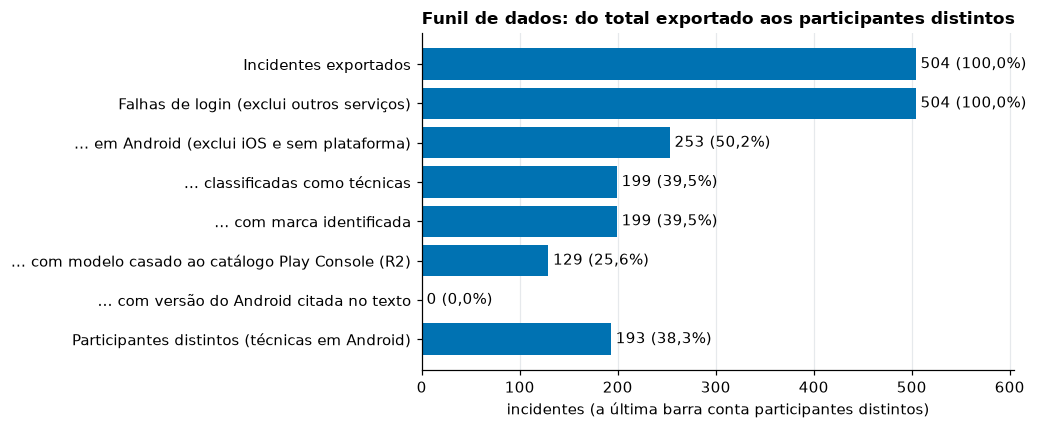

In [11]:
fun = funil(inc, tec)
fig, ax = plt.subplots(figsize=(9.5, 4))
rot, val, pc = fun["etapa"][::-1], fun["n"][::-1], fun["pct_total"][::-1]
ax.barh(rot, val, color=COR["azul"])
for y, (n, p) in enumerate(zip(val, pc)):
    ax.text(n + 5, y, f"{int(n)} ({br(p)}%)", va="center")
ax.set_xlim(0, fun["n"].max() * 1.2)
ax.set_xlabel("incidentes (a última barra conta participantes distintos)")
ax.set_title("Funil de dados: do total exportado aos participantes distintos")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [12]:
f = fun.set_index("ordem")["n"]
md_texto(
    f"Dos {f[1]} incidentes, {f[3]} ({br(100 * f[3] / f[1])}%) são de Android e {f[4]} foram classificados como "
    f"técnicos. Só {f[6]} ({br(100 * f[6] / f[1])}%) têm modelo casado ao catálogo, e nenhum cita a versão do Android "
    f"({f[7]}). Os {f[4]} incidentes técnicos vêm de {f[8]} participantes distintos.",
    "O funil define o tamanho real de cada análise. A queda mais forte é o casamento com o catálogo, e é ela que limita "
    "a análise por modelo, chip e memória.")

**O que este dado está nos dizendo?** Dos 504 incidentes, 253 (50,2%) são de Android e 199 foram classificados como técnicos. Só 129 (25,6%) têm modelo casado ao catálogo, e nenhum cita a versão do Android (0). Os 199 incidentes técnicos vêm de 193 participantes distintos.

**Por que isso é relevante?** O funil define o tamanho real de cada análise. A queda mais forte é o casamento com o catálogo, e é ela que limita a análise por modelo, chip e memória.

## 3. Panorama dos incidentes

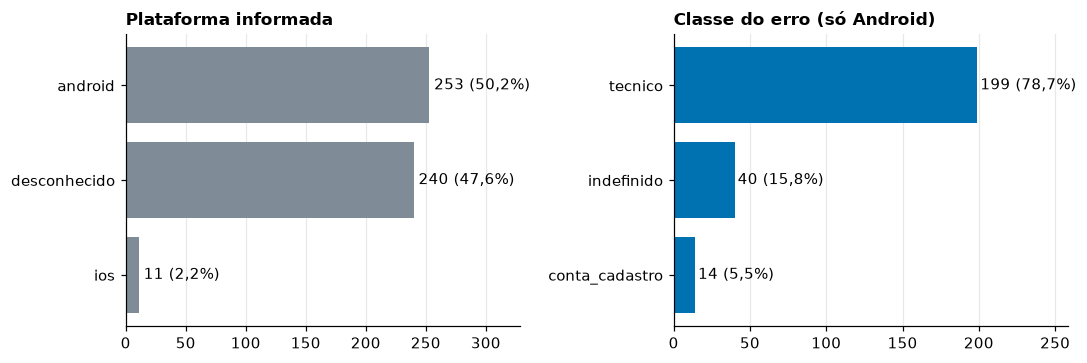

In [13]:
android = inc[inc["so"] == "android"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
so_n = inc["so"].value_counts()
a1.barh(so_n.index[::-1], so_n.values[::-1], color=COR["neutro"])
for y, n in enumerate(so_n.values[::-1]):
    a1.text(n + 4, y, f"{n} ({br(100 * n / len(inc))}%)", va="center")
a1.set_xlim(0, so_n.max() * 1.3); a1.set_title("Plataforma informada"); a1.grid(axis="y", visible=False)
cl = android["classe_erro"].value_counts()
a2.barh(cl.index[::-1], cl.values[::-1], color=COR["azul"])
for y, n in enumerate(cl.values[::-1]):
    a2.text(n + 2, y, f"{n} ({br(100 * n / len(android))}%)", va="center")
a2.set_xlim(0, cl.max() * 1.3); a2.set_title("Classe do erro (só Android)"); a2.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [14]:
md_texto(
    f"{br(100 * so_n.get('android', 0) / len(inc))}% dos incidentes indicam Android, e "
    f"{br(100 * so_n.get('desconhecido', 0) / len(inc))}% não informa a plataforma. Entre os de Android, "
    f"{br(100 * cl.get('tecnico', 0) / len(android))}% são técnicos; o restante é erro de conta ou cadastro, ou não "
    "pôde ser classificado.",
    "Só os incidentes técnicos em Android entram nas taxas. Os de conta e cadastro (senha, matrícula, bloqueio) não "
    "dependem do aparelho, e iOS fica de fora por falta de catálogo de aparelhos.")

**O que este dado está nos dizendo?** 50,2% dos incidentes indicam Android, e 47,6% não informa a plataforma. Entre os de Android, 78,7% são técnicos; o restante é erro de conta ou cadastro, ou não pôde ser classificado.

**Por que isso é relevante?** Só os incidentes técnicos em Android entram nas taxas. Os de conta e cadastro (senha, matrícula, bloqueio) não dependem do aparelho, e iOS fica de fora por falta de catálogo de aparelhos.

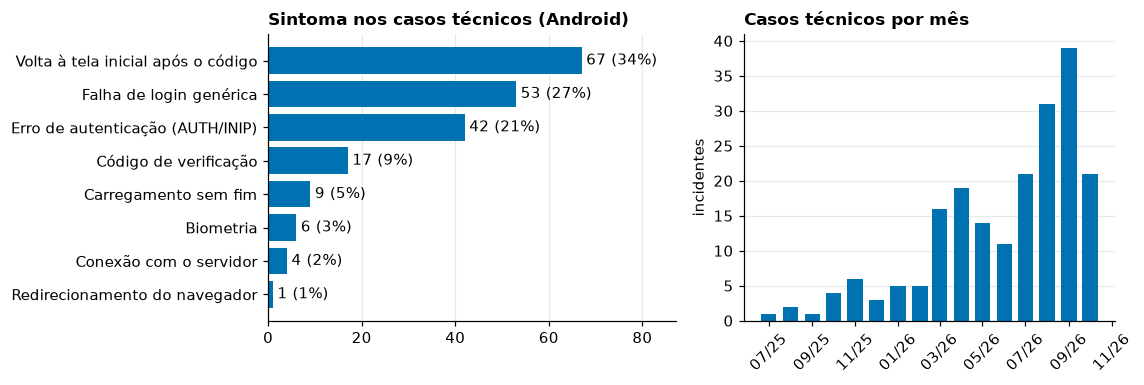

In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
sub = tec["subtipo_erro"].value_counts()
rot_sub = [SINTOMAS.get(k, k) for k in sub.index]
a1.barh(rot_sub[::-1], sub.values[::-1], color=COR["azul"])
for y, n in enumerate(sub.values[::-1]):
    a1.text(n + 1, y, f"{n} ({br(100 * n / len(tec), 0)}%)", va="center")
a1.set_xlim(0, sub.max() * 1.3); a1.set_title("Sintoma nos casos técnicos (Android)"); a1.grid(axis="y", visible=False)
mes = tec.set_index("opened_at").resample("MS").size()
a2.bar(mes.index, mes.values, width=22, color=COR["azul"])
a2.set_title("Casos técnicos por mês"); a2.set_ylabel("incidentes")
a2.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%m/%y"))
a2.tick_params(axis="x", rotation=45); a2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [16]:
ult3 = mes.tail(3).sum()
md_texto(
    f"O sintoma mais frequente é **{rot_sub[0].lower()}** ({br(100 * sub.iloc[0] / len(tec), 0)}% dos casos "
    f"técnicos). Os últimos 3 meses concentram {br(100 * ult3 / len(tec), 0)}% dos casos.",
    "O sintoma orienta o teste da equipe do aplicativo. A concentração no fim do período é um parâmetro do simulador "
    "(`forma_tempo`), que reproduz o comportamento da base real; ela não é uma descoberta desta base.")

**O que este dado está nos dizendo?** O sintoma mais frequente é **volta à tela inicial após o código** (34% dos casos técnicos). Os últimos 3 meses concentram 46% dos casos.

**Por que isso é relevante?** O sintoma orienta o teste da equipe do aplicativo. A concentração no fim do período é um parâmetro do simulador (`forma_tempo`), que reproduz o comportamento da base real; ela não é uma descoberta desta base.

## 4. Taxa por grupo: a contagem absoluta engana

Um grupo grande sempre terá mais chamados. A comparação justa usa a **taxa**: participantes afetados por mil
aparelhos ativos do grupo, com intervalo de confiança de 95% (Poisson exato) e correção de Benjamini-Hochberg
para os testes múltiplos. Os eixos de taxa partem do zero.

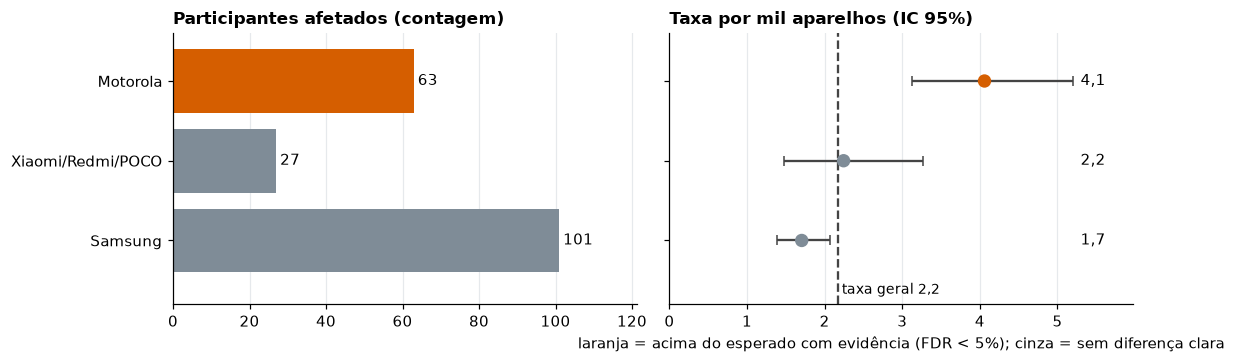

In [17]:
tx = analise.taxas(tec, pop)
m = tx[tx["dimensao"] == "marca"].sort_values("taxa_por_mil")
cor_m = np.where(m["significativo"] == 1, COR["destaque"], COR["neutro"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.4), sharey=True)
a1.barh(m["grupo"], m["afetados"], color=cor_m)
for y, n in enumerate(m["afetados"]):
    a1.text(n + 1, y, str(int(n)), va="center")
a1.set_title("Participantes afetados (contagem)"); a1.set_xlim(0, m["afetados"].max() * 1.2); a1.grid(axis="y", visible=False)
y = np.arange(len(m))
a2.errorbar(m["taxa_por_mil"], y, xerr=[m["taxa_por_mil"] - m["ic_inf"], m["ic_sup"] - m["taxa_por_mil"]],
            fmt="none", ecolor="#444", capsize=3)
a2.scatter(m["taxa_por_mil"], y, c=cor_m, s=60, zorder=3)
a2.axvline(taxa_g, ls="--", color="#444"); a2.text(taxa_g, -.62, f" taxa geral {br(taxa_g, 1)}", fontsize=9, va="center")
a2.set_ylim(-.8, len(m) - .4)
for yy, v in zip(y, m["taxa_por_mil"]):
    a2.text(m["ic_sup"].max() * 1.02, yy, f"{br(v)}", va="center", ha="left")
a2.set_xlim(0, m["ic_sup"].max() * 1.15); a2.set_title("Taxa por mil aparelhos (IC 95%)"); a2.grid(axis="y", visible=False)
a2.set_xlabel("laranja = acima do esperado com evidência (FDR < 5%); cinza = sem diferença clara")
plt.tight_layout(); plt.show()

In [18]:
topo_n = m.sort_values("afetados").iloc[-1]
topo_t = m.sort_values("taxa_por_mil").iloc[-1]
md_texto(
    f"**{topo_n['grupo']}** tem mais afetados em número absoluto ({int(topo_n['afetados'])}), mas **{topo_t['grupo']}** tem "
    f"a maior taxa ({br(topo_t['taxa_por_mil'])} por mil, IC 95%: {br(topo_t['ic_inf'])} a {br(topo_t['ic_sup'])}; "
    f"risco relativo de {br(topo_t['risco_relativo'])} em relação às demais marcas). A taxa geral é {br(taxa_g, 2)} por mil.",
    "A marca com mais chamados é a que tem mais aparelhos instalados, não necessariamente a mais problemática. "
    "Priorizar pelo número absoluto levaria a investigar o grupo errado.")

**O que este dado está nos dizendo?** **Samsung** tem mais afetados em número absoluto (101), mas **Motorola** tem a maior taxa (4,1 por mil, IC 95%: 3,1 a 5,2; risco relativo de 2,3 em relação às demais marcas). A taxa geral é 2,17 por mil.

**Por que isso é relevante?** A marca com mais chamados é a que tem mais aparelhos instalados, não necessariamente a mais problemática. Priorizar pelo número absoluto levaria a investigar o grupo errado.

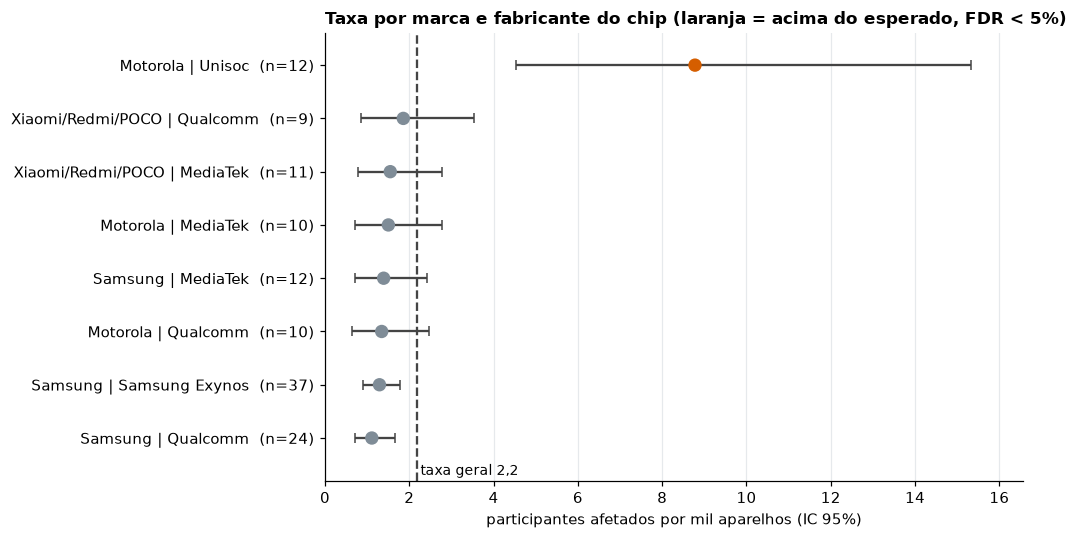

In [19]:
s = tx[(tx["dimensao"] == "marca_soc") & (tx["afetados"] > 0)].sort_values("taxa_por_mil")
cor_s = np.where(s["significativo"] == 1, COR["destaque"], COR["neutro"])
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(9.5, 0.45 * len(s) + 1.4))
ax.errorbar(s["taxa_por_mil"], y, xerr=[s["taxa_por_mil"] - s["ic_inf"], s["ic_sup"] - s["taxa_por_mil"]],
            fmt="none", ecolor="#444", capsize=3)
ax.scatter(s["taxa_por_mil"], y, c=cor_s, s=60, zorder=3)
ax.set_yticks(y, [f"{g}  (n={int(a)})" for g, a in zip(s["grupo"], s["afetados"])])
ax.axvline(taxa_g, ls="--", color="#444"); ax.text(taxa_g, -.62, f" taxa geral {br(taxa_g, 1)}", fontsize=9, va="center")
ax.set_ylim(-.8, len(s) - .4); ax.set_xlim(0, s["ic_sup"].max() * 1.08); ax.set_xlabel("participantes afetados por mil aparelhos (IC 95%)")
ax.set_title("Taxa por marca e fabricante do chip (laranja = acima do esperado, FDR < 5%)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [20]:
d = s.iloc[-1]
sig = s[s["significativo"] == 1]
md_texto(
    f"O grupo **{d['grupo']}** destaca-se: {br(d['taxa_por_mil'])} por mil (IC 95%: {br(d['ic_inf'])} a {br(d['ic_sup'])}), "
    f"risco relativo de {br(d['risco_relativo'])}, com {int(d['afetados'])} participantes afetados. "
    f"Grupos acima do esperado após a correção para testes múltiplos: {len(sig)} de {len(s)}.",
    "Cruzar marca com fabricante do chip separa um efeito que a marca sozinha esconde: dentro de uma mesma marca, só "
    "uma família de chip concentra os casos. **Atenção:** o simulador foi calibrado para reproduzir esse grupo "
    "(parâmetro `multiplicador_culpado`). Aqui o resultado valida que o método recupera o efeito; não é uma "
    "descoberta sobre aparelhos reais.")

**O que este dado está nos dizendo?** O grupo **Motorola | Unisoc** destaca-se: 8,8 por mil (IC 95%: 4,5 a 15,3), risco relativo de 6,6, com 12 participantes afetados. Grupos acima do esperado após a correção para testes múltiplos: 1 de 8.

**Por que isso é relevante?** Cruzar marca com fabricante do chip separa um efeito que a marca sozinha esconde: dentro de uma mesma marca, só uma família de chip concentra os casos. **Atenção:** o simulador foi calibrado para reproduzir esse grupo (parâmetro `multiplicador_culpado`). Aqui o resultado valida que o método recupera o efeito; não é uma descoberta sobre aparelhos reais.

In [21]:
mod = tx[tx["dimensao"] == "modelo"].sort_values("taxa_por_mil", ascending=False)
mod = mod.assign(**{"IC 95%": [f"{br(a)} a {br(b)}" for a, b in zip(mod["ic_inf"], mod["ic_sup"])]})
mod[["grupo", "afetados", "base", "taxa_por_mil", "IC 95%", "risco_relativo", "p_ajustado", "significativo"]].round(
    {"base": 0, "taxa_por_mil": 2, "risco_relativo": 2, "p_ajustado": 4}).reset_index(drop=True)

,grupo,afetados,base,taxa_por_mil,IC 95%,risco_relativo,p_ajustado,significativo
0,moto g35,7,708.0,9.89,"4,0 a 20,4",7.15,0.0747,0


In [22]:
md_texto(
    f"Modelos com {config.K_MIN} ou mais participantes afetados, os únicos que aparecem com taxa: {len(mod)}. O de maior "
    f"taxa é **{mod.iloc[0]['grupo']}** ({br(mod.iloc[0]['taxa_por_mil'])} por mil, {int(mod.iloc[0]['afetados'])} afetados, "
    "sem significância após a correção). Os demais ficam suprimidos por privacidade, e modelos com poucos afetados têm "
    "intervalos largos e podem ter taxa alta só pelo acaso.",
    "Por isso o ranking do dashboard usa uma taxa ajustada e só marca como crítico o perfil com pelo menos 5 "
    "participantes e evidência estatística, para um modelo com 1 caso em poucos aparelhos não ultrapassar um de "
    "evidência sólida.")

**O que este dado está nos dizendo?** Modelos com 5 ou mais participantes afetados, os únicos que aparecem com taxa: 1. O de maior taxa é **moto g35** (9,9 por mil, 7 afetados, sem significância após a correção). Os demais ficam suprimidos por privacidade, e modelos com poucos afetados têm intervalos largos e podem ter taxa alta só pelo acaso.

**Por que isso é relevante?** Por isso o ranking do dashboard usa uma taxa ajustada e só marca como crítico o perfil com pelo menos 5 participantes e evidência estatística, para um modelo com 1 caso em poucos aparelhos não ultrapassar um de evidência sólida.

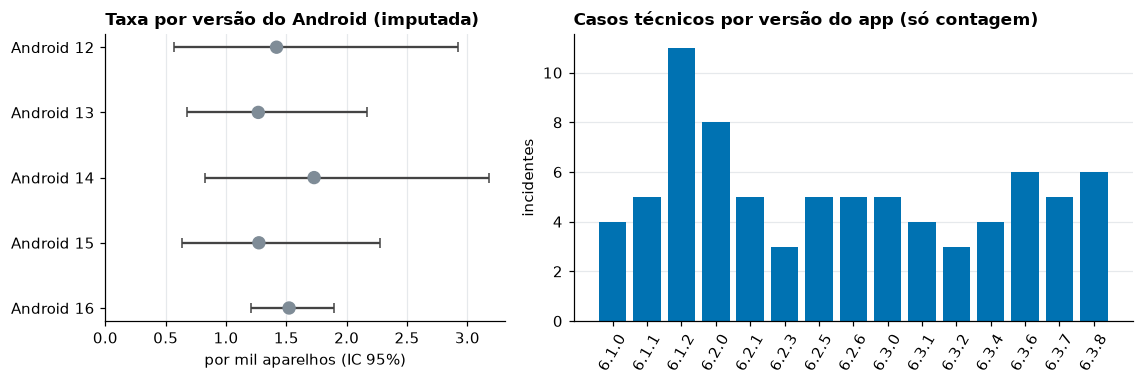

In [23]:
av = tx[(tx["dimensao"] == "android") & (tx["afetados"] > 0)].sort_values("grupo")
apps = tec["app_version"].dropna().value_counts().sort_index()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
y = np.arange(len(av))
a1.errorbar(av["taxa_por_mil"], y, xerr=[av["taxa_por_mil"] - av["ic_inf"], av["ic_sup"] - av["taxa_por_mil"]],
            fmt="none", ecolor="#444", capsize=3)
a1.scatter(av["taxa_por_mil"], y, c=np.where(av["significativo"] == 1, COR["destaque"], COR["neutro"]), s=60, zorder=3)
a1.set_yticks(y, [f"Android {g}" for g in av["grupo"]]); a1.set_xlim(0); a1.invert_yaxis()
a1.set_xlabel("por mil aparelhos (IC 95%)"); a1.set_title("Taxa por versão do Android (imputada)"); a1.grid(axis="y", visible=False)
a2.bar(apps.index, apps.values, color=COR["azul"]); a2.set_title("Casos técnicos por versão do app (só contagem)")
a2.tick_params(axis="x", rotation=60); a2.set_ylabel("incidentes"); a2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [24]:
md_texto(
    f"A versão do Android vem inteira da imputação (cada modelo conta na versão mais recente que suporta), então o "
    f"gráfico da esquerda mostra os modelos agrupados por essa versão. Para a versão do app só há contagem de casos: "
    f"o catálogo não informa quantos aparelhos usam cada versão. A versão com mais casos é a "
    f"**{apps.idxmax()}** ({int(apps.max())} incidentes).",
    "Nenhum dos dois gráficos confirma que uma versão do Android ou do app causa as falhas. Sem a versão instalada nos "
    "chamados e sem o denominador por versão do app, a comparação seria enganosa; a recomendação é registrar essas "
    "versões nos chamados novos.")

**O que este dado está nos dizendo?** A versão do Android vem inteira da imputação (cada modelo conta na versão mais recente que suporta), então o gráfico da esquerda mostra os modelos agrupados por essa versão. Para a versão do app só há contagem de casos: o catálogo não informa quantos aparelhos usam cada versão. A versão com mais casos é a **6.1.2** (11 incidentes).

**Por que isso é relevante?** Nenhum dos dois gráficos confirma que uma versão do Android ou do app causa as falhas. Sem a versão instalada nos chamados e sem o denominador por versão do app, a comparação seria enganosa; a recomendação é registrar essas versões nos chamados novos.

## 5. Perfis de aparelho

Um **perfil** é um modelo do catálogo. O ranking usa uma taxa ajustada (cada perfil recebe o equivalente a 500
aparelhos com a taxa geral) e a regra de privacidade `K_MIN`: perfis com menos de 5 participantes aparecem sem
números. É a mesma tabela que alimenta o mapa e o ranking do dashboard. Intervalos acima de 120 por mil são
cortados no gráfico (▶) para não achatar os demais; o valor completo está na tabela do ranking.

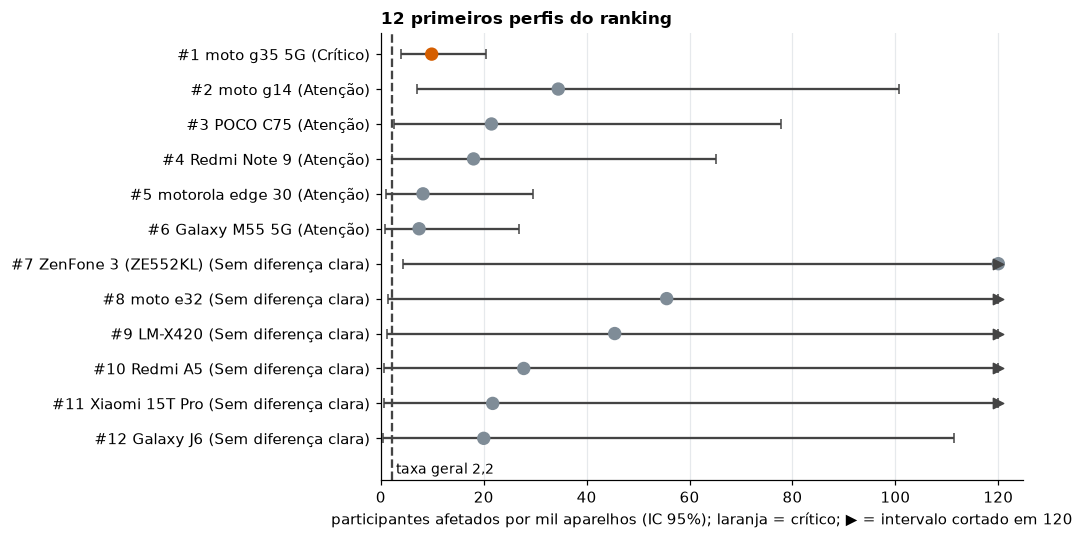

,perfis
status_rotulo,
Sem diferença clara,91
Atenção,12
Sem base para taxa,4
Crítico,1


In [25]:
perf = perfis.construir(inc, cat, pop, tec)
perf["status_rotulo"] = perf["status"].map(lambda s: STATUS[s][0])
resumo_status = perf["status_rotulo"].value_counts().rename("perfis").to_frame()
top = perf.dropna(subset=["rank"]).sort_values("rank").head(12).iloc[::-1]
LIM = 120                                  # mesmo teto do ranking do dashboard
y = np.arange(len(top))
cortado = top["ic_sup"] > LIM
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.errorbar(top["taxa_por_mil"].clip(upper=LIM), y,
            xerr=[(top["taxa_por_mil"].clip(upper=LIM) - top["ic_inf"]).clip(lower=0),
                  (top["ic_sup"].clip(upper=LIM) - top["taxa_por_mil"].clip(upper=LIM)).clip(lower=0)],
            fmt="none", ecolor="#444", capsize=3)
ax.scatter(top["taxa_por_mil"].clip(upper=LIM), y, s=60, zorder=3,
           c=np.where(top["status"] == "critico", COR["destaque"], COR["neutro"]))
ax.scatter([LIM] * int(cortado.sum()), y[cortado.values], marker=">", s=45, color="#444", zorder=4)
ax.set_yticks(y, [f"#{int(r)} {p} ({s})" for r, p, s in zip(top["rank"], top["perfil"], top["status_rotulo"])])
ax.axvline(taxa_g, ls="--", color="#444"); ax.text(taxa_g, -.9, f" taxa geral {br(taxa_g, 1)}", fontsize=9, va="center")
ax.set_ylim(-1.2, len(top) - .4); ax.set_xlim(0, LIM * 1.04)
ax.set_xlabel(f"participantes afetados por mil aparelhos (IC 95%); laranja = crítico; ▶ = intervalo cortado em {LIM}")
ax.set_title("12 primeiros perfis do ranking"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
resumo_status

In [26]:
crit = perf[perf["status"] == "critico"].sort_values("rank")
nomes = ", ".join(crit["perfil"]) if len(crit) else "nenhum"
md_texto(
    f"{len(perf)} perfis foram analisados. Em status crítico: {len(crit)} ({nomes}). Sem base para taxa: "
    f"{int((perf['status'] == 'sem_base').sum())}. Com menos de {config.K_MIN} participantes (sem números, por "
    f"privacidade): {int((perf['afetados'] < config.K_MIN).sum())}.",
    "O ranking transforma a análise em uma lista de teste para a equipe do aplicativo, e a regra `K_MIN` protege a "
    "privacidade: um grupo pequeno poderia identificar pessoas.")

**O que este dado está nos dizendo?** 108 perfis foram analisados. Em status crítico: 1 (moto g35 5G). Sem base para taxa: 4. Com menos de 5 participantes (sem números, por privacidade): 103.

**Por que isso é relevante?** O ranking transforma a análise em uma lista de teste para a equipe do aplicativo, e a regra `K_MIN` protege a privacidade: um grupo pequeno poderia identificar pessoas.

## 6. Modelo de Poisson

Regressão de Poisson por célula (modelo × versão do Android), com a base de aparelhos como **exposição**
(*offset*). O **IRR** (razão de taxas) diz quantas vezes a taxa de um grupo é maior que a da categoria de referência
(**Samsung, Android 14, 8 GB**), controlando pelos outros atributos. IRR = 1 significa igual à referência; a escala
é logarítmica.

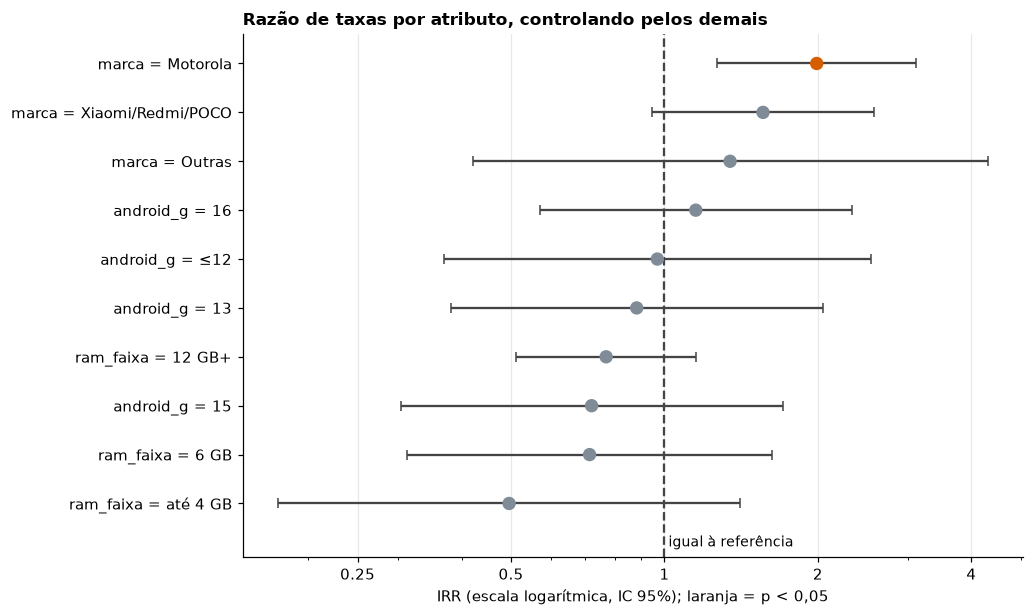

,termo,irr,ic_inf,ic_sup,p_valor
0,ram_faixa = até 4 GB,0.496,0.175,1.407,0.187
1,ram_faixa = 6 GB,0.713,0.313,1.624,0.421
2,android_g = 15,0.720,0.303,1.706,0.455
3,ram_faixa = 12 GB+,0.768,0.512,1.154,0.204
4,android_g = 13,0.882,0.381,2.044,0.770
5,android_g = ≤12,0.968,0.369,2.541,0.948
6,android_g = 16,1.152,0.569,2.333,0.694
7,marca = Outras,1.345,0.420,4.304,0.617
8,marca = Xiaomi/Redmi/POCO,1.561,0.946,2.577,0.082
9,marca = Motorola,1.990,1.268,3.123,0.003


In [27]:
poi = analise.modelo_poisson(tec, pop)
poi = poi[poi["ic_sup"] < 1e6].sort_values("irr").reset_index(drop=True)
y = np.arange(len(poi))
sig = poi["p_valor"] < 0.05
fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(poi) + 1.5))
ax.errorbar(poi["irr"], y, xerr=[poi["irr"] - poi["ic_inf"], poi["ic_sup"] - poi["irr"]], fmt="none", ecolor="#444", capsize=3)
ax.scatter(poi["irr"], y, s=60, zorder=3, c=np.where(sig, COR["destaque"], COR["neutro"]))
ax.set_yticks(y, poi["termo"]); ax.set_xscale("log")
ax.set_xticks([.25, .5, 1, 2, 4]); ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%g")); ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.axvline(1, ls="--", color="#444"); ax.text(1, -.8, " igual à referência", fontsize=9, va="center"); ax.set_ylim(-1.1, len(poi) - .4)
ax.set_xlabel("IRR (escala logarítmica, IC 95%); laranja = p < 0,05")
ax.set_title("Razão de taxas por atributo, controlando pelos demais"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
poi[["termo", "irr", "ic_inf", "ic_sup", "p_valor"]].round(3)

In [28]:
maior = poi[sig].sort_values("irr").iloc[-1] if sig.any() else None
md_texto(
    (f"O maior efeito significativo é **{maior['termo']}**, com IRR de {br(maior['irr'])} (IC 95%: {br(maior['ic_inf'])} "
     f"a {br(maior['ic_sup'])}). " if maior is not None else "Nenhum atributo é significativo. ") +
    f"Termos com p < 0,05: {int(sig.sum())} de {len(poi)}. Intervalos que cruzam 1 indicam que a diferença pode ser acaso.",
    "O modelo separa o efeito da marca do efeito da versão do Android e da memória, o que a taxa por grupo sozinha não "
    "faz. Ele descreve **associação**: como a versão do Android é imputada, os coeficientes de versão não demonstram "
    "risco real de uma versão específica.")

**O que este dado está nos dizendo?** O maior efeito significativo é **marca = Motorola**, com IRR de 2,0 (IC 95%: 1,3 a 3,1). Termos com p < 0,05: 1 de 10. Intervalos que cruzam 1 indicam que a diferença pode ser acaso.

**Por que isso é relevante?** O modelo separa o efeito da marca do efeito da versão do Android e da memória, o que a taxa por grupo sozinha não faz. Ele descreve **associação**: como a versão do Android é imputada, os coeficientes de versão não demonstram risco real de uma versão específica.

## 7. Grafo de atributos

Cada **nó** é um atributo (marca, modelo, chip, Android, versão do app, memória, tipo de erro). Dois nós ficam
ligados quando aparecem **no mesmo incidente técnico**; a espessura da aresta é o número de incidentes. O **lift**
maior que 1 indica que o atributo aparece nos incidentes mais do que sua participação na base.

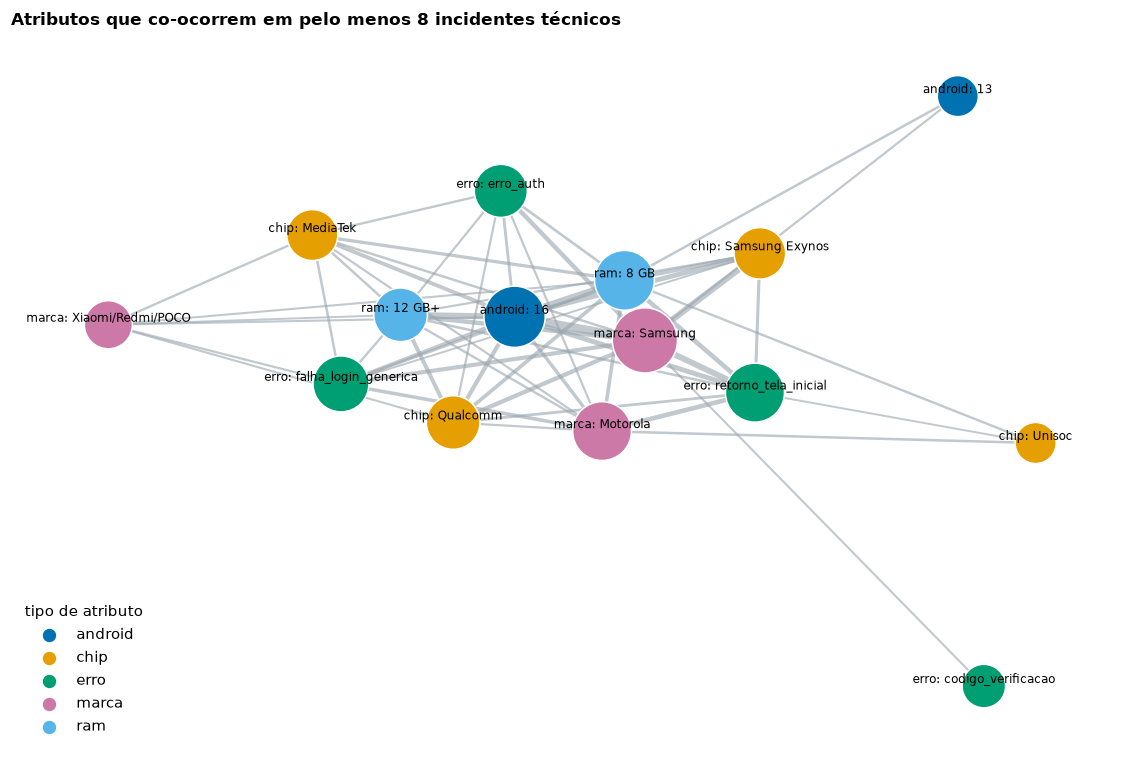

In [29]:
G = grafo.construir(tec, pop)
nos_g, ar_g = grafo.para_tabelas(G)
fortes = [(a, b) for a, b, d in G.edges(data=True) if d["peso"] >= 8]
H = G.edge_subgraph(fortes).copy()
pos = nx.spring_layout(H, weight="peso", seed=config.SEED, k=1.2)
attr = nos_g.set_index("no")
tipos = sorted(attr.loc[list(H.nodes), "tipo"].unique())
paleta = dict(zip(tipos, [COR["azul"], COR["amarelo"], COR["verde"], COR["roxo"], COR["ceu"], COR["destaque"], "#444444", "#999999"]))
fig, ax = plt.subplots(figsize=(10.5, 7))
pesos = np.array([H[a][b]["peso"] for a, b in H.edges])
nx.draw_networkx_edges(H, pos, width=.5 + 5 * pesos / pesos.max(), edge_color="#9aa5ae", alpha=.6, ax=ax)
tam = 120 + 1700 * (attr.loc[list(H.nodes), "incidentes"] / attr["incidentes"].max()) ** .5
nx.draw_networkx_nodes(H, pos, node_size=tam.values, node_color=[paleta[attr.loc[n, "tipo"]] for n in H.nodes],
                       edgecolors="white", ax=ax)
nx.draw_networkx_labels(H, pos, font_size=8, verticalalignment="bottom", ax=ax)
for t, c in paleta.items():
    ax.scatter([], [], c=c, s=60, label=t)
ax.legend(title="tipo de atributo", loc="lower left", frameon=False)
ax.set_title("Atributos que co-ocorrem em pelo menos 8 incidentes técnicos"); ax.axis("off"); ax.grid(False)
plt.tight_layout(); plt.show()

In [30]:
centrais = nos_g.sort_values("centralidade", ascending=False).head(8)[["no", "incidentes", "lift", "centralidade", "comunidade"]]
display(Markdown("**Atributos mais centrais**"))
display(centrais.round(3).reset_index(drop=True))
pares = ar_g.dropna(subset=["lift"]).sort_values("lift", ascending=False).head(8)
display(Markdown("**Combinações super-representadas (maior lift)**"))
display(pares.round(2).reset_index(drop=True))

**Atributos mais centrais**

,no,incidentes,lift,centralidade,comunidade
0,android: 16,79,1.049,0.452,1
1,marca: Samsung,103,0.777,0.447,1
2,ram: 8 GB,71,1.107,0.382,1
3,erro: retorno_tela_inicial,67,NaN,0.298,1
4,ram: 12 GB+,44,0.993,0.255,2
5,chip: Samsung Exynos,37,0.889,0.253,1
6,chip: Qualcomm,44,0.879,0.240,2
7,erro: falha_login_generica,53,NaN,0.205,2


**Combinações super-representadas (maior lift)**

,origem,destino,peso,lift
0,marca: Motorola,modelo: moto g35,7,6.81
1,ram: 8 GB,chip: Unisoc,11,6.07
2,marca: Motorola,chip: Unisoc,12,6.05
3,android: 16,chip: Unisoc,7,5.44
4,marca: Motorola,ram: 8 GB,19,2.39
5,marca: Motorola,android: 16,18,2.13
6,android: 14,ram: 8 GB,7,1.34
7,marca: Xiaomi/Redmi/POCO,chip: Qualcomm,9,1.28


In [31]:
c1 = centrais.iloc[0]; p1 = pares.iloc[0]
md_texto(
    f"O atributo mais central é **{c1['no']}** ({int(c1['incidentes'])} incidentes). A combinação mais "
    f"super-representada é **{p1['origem']} + {p1['destino']}** (lift {br(p1['lift'], 2)}, {int(p1['peso'])} incidentes juntos).",
    "O grafo revela combinações (por exemplo, marca e chip) que aparecem juntas nos casos mais do que o acaso "
    "sugeriria, e ajuda a escolher quais cruzamentos testar. Co-ocorrência é descrição, não explicação.")

**O que este dado está nos dizendo?** O atributo mais central é **android: 16** (79 incidentes). A combinação mais super-representada é **marca: Motorola + modelo: moto g35** (lift 6,81, 7 incidentes juntos).

**Por que isso é relevante?** O grafo revela combinações (por exemplo, marca e chip) que aparecem juntas nos casos mais do que o acaso sugeriria, e ajuda a escolher quais cruzamentos testar. Co-ocorrência é descrição, não explicação.

## 8. Verificação de reprodutibilidade

Tudo acima foi recalculado do zero, a partir do catálogo bruto e do simulador com semente fixa. A tabela compara
cada resultado com o arquivo que o pipeline (`python -m src.pipeline --sem-banco`) grava em `data/processed/`. Se
alguma linha falhar, o notebook para.

In [32]:
P = config.DATA_PROCESSED


def numeros_iguais(a, b, cols):
    return bool(np.allclose(a[cols].to_numpy(float), b[cols].to_numpy(float), equal_nan=True))


def vazio(s):
    return s.astype("string").fillna("∅")


ref = {n: pd.read_csv(P / f"{n}.csv") for n in ["resultados_taxas", "modelo_poisson", "incidentes_tratados_simulado",
                                                 "grafo_nos", "grafo_arestas", "lineage", "perfis"]}
tx_c = tx.reset_index(drop=True)
poi_c = analise.modelo_poisson(tec, pop).reset_index(drop=True)
num_tx = tx_c.select_dtypes("number").columns.tolist()
checagens = {
    "Taxas por grupo (resultados_taxas.csv)": (tx_c["grupo"].tolist() == ref["resultados_taxas"]["grupo"].tolist()
                                               and numeros_iguais(tx_c, ref["resultados_taxas"], num_tx)),
    "Modelo de Poisson (modelo_poisson.csv)": numeros_iguais(poi_c, ref["modelo_poisson"], ["irr", "ic_inf", "ic_sup", "p_valor"]),
    "Incidentes tratados (incidentes_tratados_simulado.csv)": (
        all((vazio(inc[c]).to_numpy() == vazio(ref["incidentes_tratados_simulado"][c]).to_numpy()).all()
            for c in ["inc_id", "so", "classe_erro", "subtipo_erro"])
        and numeros_iguais(inc, ref["incidentes_tratados_simulado"], ["model_id"])),
    "Nós do grafo (grafo_nos.csv)": numeros_iguais(nos_g.reset_index(drop=True), ref["grafo_nos"], ["incidentes", "lift", "grau_ponderado", "centralidade"]),
    "Arestas do grafo (grafo_arestas.csv)": numeros_iguais(ar_g.reset_index(drop=True), ref["grafo_arestas"], ["peso", "lift"]),
    "Funil (lineage.csv)": numeros_iguais(fun, ref["lineage"], ["ordem", "n"]),
    "Perfis (perfis.csv)": (numeros_iguais(perf, ref["perfis"], ["taxa_por_mil", "afetados"])
                            and perf["status"].tolist() == ref["perfis"]["status"].tolist()),
}
verif = pd.DataFrame({"resultado": ["confere" if ok else "DIVERGE" for ok in checagens.values()]}, index=list(checagens))
assert all(checagens.values()), "algum resultado recalculado diverge de data/processed"
verif

,resultado
Taxas por grupo (resultados_taxas.csv),confere
Modelo de Poisson (modelo_poisson.csv),confere
Incidentes tratados (incidentes_tratados_simulado.csv),confere
Nós do grafo (grafo_nos.csv),confere
Arestas do grafo (grafo_arestas.csv),confere
Funil (lineage.csv),confere
Perfis (perfis.csv),confere


In [33]:
md_texto(
    "Os resultados recalculados no notebook são idênticos aos arquivos do pipeline.",
    "A reprodutibilidade é o critério de validade do trabalho: qualquer pessoa com o repositório obtém os mesmos "
    "números, sem acesso ao banco nem a dados reais. A parte real da análise roda localmente "
    "(`python -m src.pipeline --fonte real_anonimizado`), grava em `data/private/real/` e não entra neste notebook.")

**O que este dado está nos dizendo?** Os resultados recalculados no notebook são idênticos aos arquivos do pipeline.

**Por que isso é relevante?** A reprodutibilidade é o critério de validade do trabalho: qualquer pessoa com o repositório obtém os mesmos números, sem acesso ao banco nem a dados reais. A parte real da análise roda localmente (`python -m src.pipeline --fonte real_anonimizado`), grava em `data/private/real/` e não entra neste notebook.

## 9. Limitações e conclusões

**Limitações**
- **Dados simulados.** Os incidentes são simulados e calibrados com agregados da análise real. O efeito do grupo de
  maior taxa foi plantado no simulador; este notebook mostra que o método o recupera, e não que ele exista em
  aparelhos reais.
- **Versão do Android imputada.** Nenhum incidente cita a versão; ela vem do catálogo (regra `sdk_max_do_modelo`).
  Os resultados por versão não demonstram risco de uma versão específica.
- **Base por modelo, não por versão.** O Play Console informa instalações por modelo, e a base por versão do app
  não existe, então a versão do app só tem contagem, sem taxa.
- **Amostra efetiva pequena.** Só uma parte dos incidentes chega ao modelo do catálogo (funil), o que alarga os
  intervalos de confiança e deixa muitos perfis abaixo de `K_MIN`.
- **Rede e operadora** quase nunca são informadas e ficam fora das conclusões.
- **Viés de quem reporta.** Só entra quem abriu chamado. Um incidente não é uma pessoa nem um aparelho; as taxas
  contam participantes distintos.
- **iOS** fica fora das taxas por falta de catálogo de aparelhos.

**Conclusões**
1. A contagem absoluta e a taxa apontam para grupos diferentes. A decisão de onde investigar deve usar a taxa.
2. Cruzar marca com fabricante do chip separa grupos que a marca sozinha mistura.
3. O pipeline é reprodutível do início ao fim, com semente fixa e verificação automática contra os arquivos do repositório.
4. Qualquer resultado é uma **associação a ser validada** pela equipe do aplicativo. A hipótese técnica de cada perfil
   não é uma causa comprovada.

**Recomendação para a coleta futura:** registrar nos chamados a versão do Android e do aplicativo instalados e o tipo
de rede. Isso transformaria hipóteses em testes diretos.